<a href="https://colab.research.google.com/github/laksamanaap/244107020021-machine-leaning-course-2026-/blob/main/JS09/JS09_Tugas_Lab1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tugas Lab 1 - Perbandingan ANNOY vs FAISS vs HNSW

In [2]:
!pip install annoy faiss-cpu hnswlib matplotlib pandas -q

import gc
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import faiss
import hnswlib
from annoy import AnnoyIndex

SEED = 42
K = 10
N_TREES = 10
EF_CONSTRUCTION = 200
M = 16
EF_SEARCH = 50

# 1000 vs 1jt, 2D vs 5D
CONFIGS = [
    (1_000, 2),
    (1_000, 5),
    (1_000_000, 2),
    (1_000_000, 5),
]
METRICS = ["euclidean", "angular"]

rng = np.random.default_rng(SEED)
print("ready")

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
ready


## Fungsi benchmark

Annoy: `euclidean` / `angular`
FAISS: IndexFlatL2 atau IndexFlatIP + normalize (buat angular)
HNSW: space `l2` / `cosine`

In [3]:
def make_data(n, dim, rng):
    X = rng.random((n, dim), dtype=np.float32)
    q = rng.random((1, dim), dtype=np.float32)
    return X, q


def bench_annoy(X, q, metric):
    n, dim = X.shape
    m = "euclidean" if metric == "euclidean" else "angular"
    idx = AnnoyIndex(dim, m)

    t0 = time.perf_counter()
    for i in range(n):
        idx.add_item(i, X[i])
    idx.build(N_TREES)
    build = time.perf_counter() - t0

    t0 = time.perf_counter()
    idx.get_nns_by_vector(q[0], K, include_distances=True)
    query = time.perf_counter() - t0

    del idx
    return build, query


def bench_faiss(X, q, metric):
    n, dim = X.shape
    if metric == "euclidean":
        index = faiss.IndexFlatL2(dim)
        data, qv = X, q
    else:
        data = X.copy()
        faiss.normalize_L2(data)
        qv = q.copy()
        faiss.normalize_L2(qv)
        index = faiss.IndexFlatIP(dim)

    t0 = time.perf_counter()
    index.add(data)
    build = time.perf_counter() - t0

    t0 = time.perf_counter()
    index.search(qv, K)
    query = time.perf_counter() - t0

    del index
    return build, query


def bench_hnsw(X, q, metric):
    n, dim = X.shape
    space = "l2" if metric == "euclidean" else "cosine"
    index = hnswlib.Index(space=space, dim=dim)

    t0 = time.perf_counter()
    index.init_index(max_elements=n, ef_construction=EF_CONSTRUCTION, M=M)
    index.add_items(X)
    build = time.perf_counter() - t0

    index.set_ef(EF_SEARCH)
    t0 = time.perf_counter()
    index.knn_query(q, k=K)
    query = time.perf_counter() - t0

    del index
    return build, query

## Jalankan semua kombinasi

 n=1.000.000

In [4]:
rows = []

for metric in METRICS:
    for n, dim in CONFIGS:
        label = f"{n}/{dim}D"
        print(f">>> {label} metric={metric}", flush=True)
        X, q = make_data(n, dim, rng)

        a_b, a_q = bench_annoy(X, q, metric)
        print(f"  Annoy  build={a_b:.4f}s query={a_q*1000:.3f}ms", flush=True)

        f_b, f_q = bench_faiss(X, q, metric)
        print(f"  FAISS  build={f_b:.4f}s query={f_q*1000:.3f}ms", flush=True)

        h_b, h_q = bench_hnsw(X, q, metric)
        print(f"  HNSW   build={h_b:.4f}s query={h_q*1000:.3f}ms", flush=True)

        rows.append({
            "Jumlah Data/Dimensi": label,
            "Metric": metric,
            "n": n,
            "dim": dim,
            "ANNOY_build_s": a_b,
            "ANNOY_query_ms": a_q * 1000,
            "FAISS_build_s": f_b,
            "FAISS_query_ms": f_q * 1000,
            "HNSW_build_s": h_b,
            "HNSW_query_ms": h_q * 1000,
        })

        del X, q
        gc.collect()

df = pd.DataFrame(rows)
df

>>> 1000/2D metric=euclidean
  Annoy  build=0.0383s query=0.116ms
  FAISS  build=0.0001s query=0.116ms
  HNSW   build=0.0948s query=0.118ms
>>> 1000/5D metric=euclidean
  Annoy  build=0.0400s query=0.105ms
  FAISS  build=0.0001s query=1.729ms
  HNSW   build=0.1283s query=0.076ms
>>> 1000000/2D metric=euclidean
  Annoy  build=33.0677s query=0.119ms
  FAISS  build=0.0049s query=8.569ms
  HNSW   build=107.9076s query=0.105ms
>>> 1000000/5D metric=euclidean
  Annoy  build=20.7299s query=0.126ms
  FAISS  build=0.0237s query=14.154ms
  HNSW   build=188.4655s query=0.142ms
>>> 1000/2D metric=angular
  Annoy  build=0.0434s query=0.083ms
  FAISS  build=0.0004s query=0.069ms
  HNSW   build=0.0416s query=0.070ms
>>> 1000/5D metric=angular
  Annoy  build=0.0216s query=0.066ms
  FAISS  build=0.0003s query=0.087ms
  HNSW   build=0.0591s query=0.083ms
>>> 1000000/2D metric=angular
  Annoy  build=92.2177s query=0.124ms
  FAISS  build=0.0029s query=2.407ms
  HNSW   build=147.3230s query=0.195ms
>>> 100

,Jumlah Data/Dimensi,Metric,n,dim,ANNOY_build_s,ANNOY_query_ms,FAISS_build_s,FAISS_query_ms,HNSW_build_s,HNSW_query_ms
0,1000/2D,euclidean,1000,2,0.038307,0.115695,0.000096,0.115649,0.094798,0.118274
1,1000/5D,euclidean,1000,5,0.040008,0.104558,0.000086,1.729497,0.128323,0.076151
2,1000000/2D,euclidean,1000000,2,33.067713,0.119236,0.004926,8.569442,107.907575,0.104659
3,1000000/5D,euclidean,1000000,5,20.729882,0.126005,0.023700,14.153775,188.465486,0.141592
4,1000/2D,angular,1000,2,0.043432,0.082935,0.000404,0.068829,0.041594,0.069752
5,1000/5D,angular,1000,5,0.021573,0.066359,0.000314,0.086914,0.059080,0.082884
6,1000000/2D,angular,1000000,2,92.217731,0.123794,0.002856,2.406653,147.322963,0.195308
7,1000000/5D,angular,1000000,5,29.293571,0.125561,0.034913,13.026503,170.079368,0.129724


## Tabel performansi (format modul)

In [5]:
# gabungin build + query biar mirip contoh tabel
def cell(b, q):
    return f"build {b:.4f}s / query {q:.3f}ms"

tabel = pd.DataFrame({
    "Jumlah Data/Dimensi": df["Jumlah Data/Dimensi"],
    "Metric": df["Metric"],
    "ANNOY": [cell(b, q) for b, q in zip(df["ANNOY_build_s"], df["ANNOY_query_ms"])],
    "FAISS": [cell(b, q) for b, q in zip(df["FAISS_build_s"], df["FAISS_query_ms"])],
    "HNSW": [cell(b, q) for b, q in zip(df["HNSW_build_s"], df["HNSW_query_ms"])],
})
tabel

,Jumlah Data/Dimensi,Metric,ANNOY,FAISS,HNSW
0,1000/2D,euclidean,build 0.0383s / query 0.116ms,build 0.0001s / query 0.116ms,build 0.0948s / query 0.118ms
1,1000/5D,euclidean,build 0.0400s / query 0.105ms,build 0.0001s / query 1.729ms,build 0.1283s / query 0.076ms
2,1000000/2D,euclidean,build 33.0677s / query 0.119ms,build 0.0049s / query 8.569ms,build 107.9076s / query 0.105ms
3,1000000/5D,euclidean,build 20.7299s / query 0.126ms,build 0.0237s / query 14.154ms,build 188.4655s / query 0.142ms
4,1000/2D,angular,build 0.0434s / query 0.083ms,build 0.0004s / query 0.069ms,build 0.0416s / query 0.070ms
5,1000/5D,angular,build 0.0216s / query 0.066ms,build 0.0003s / query 0.087ms,build 0.0591s / query 0.083ms
6,1000000/2D,angular,build 92.2177s / query 0.124ms,build 0.0029s / query 2.407ms,build 147.3230s / query 0.195ms
7,1000000/5D,angular,build 29.2936s / query 0.126ms,build 0.0349s / query 13.027ms,build 170.0794s / query 0.130ms


## Tabel terpisah: build time (detik) & query time (ms)

In [6]:
build_tbl = df[["Jumlah Data/Dimensi", "Metric", "ANNOY_build_s", "FAISS_build_s", "HNSW_build_s"]].copy()
build_tbl.columns = ["Jumlah Data/Dimensi", "Metric", "ANNOY", "FAISS", "HNSW"]
print("=== Build time (detik) ===")
display(build_tbl.round(4))

query_tbl = df[["Jumlah Data/Dimensi", "Metric", "ANNOY_query_ms", "FAISS_query_ms", "HNSW_query_ms"]].copy()
query_tbl.columns = ["Jumlah Data/Dimensi", "Metric", "ANNOY", "FAISS", "HNSW"]
print("=== Query time (ms) ===")
display(query_tbl.round(3))

=== Build time (detik) ===


,Jumlah Data/Dimensi,Metric,ANNOY,FAISS,HNSW
0,1000/2D,euclidean,0.0383,0.0001,0.0948
1,1000/5D,euclidean,0.0400,0.0001,0.1283
2,1000000/2D,euclidean,33.0677,0.0049,107.9076
3,1000000/5D,euclidean,20.7299,0.0237,188.4655
4,1000/2D,angular,0.0434,0.0004,0.0416
5,1000/5D,angular,0.0216,0.0003,0.0591
6,1000000/2D,angular,92.2177,0.0029,147.3230
7,1000000/5D,angular,29.2936,0.0349,170.0794


=== Query time (ms) ===


,Jumlah Data/Dimensi,Metric,ANNOY,FAISS,HNSW
0,1000/2D,euclidean,0.116,0.116,0.118
1,1000/5D,euclidean,0.105,1.729,0.076
2,1000000/2D,euclidean,0.119,8.569,0.105
3,1000000/5D,euclidean,0.126,14.154,0.142
4,1000/2D,angular,0.083,0.069,0.070
5,1000/5D,angular,0.066,0.087,0.083
6,1000000/2D,angular,0.124,2.407,0.195
7,1000000/5D,angular,0.126,13.027,0.130


## Visualisasi

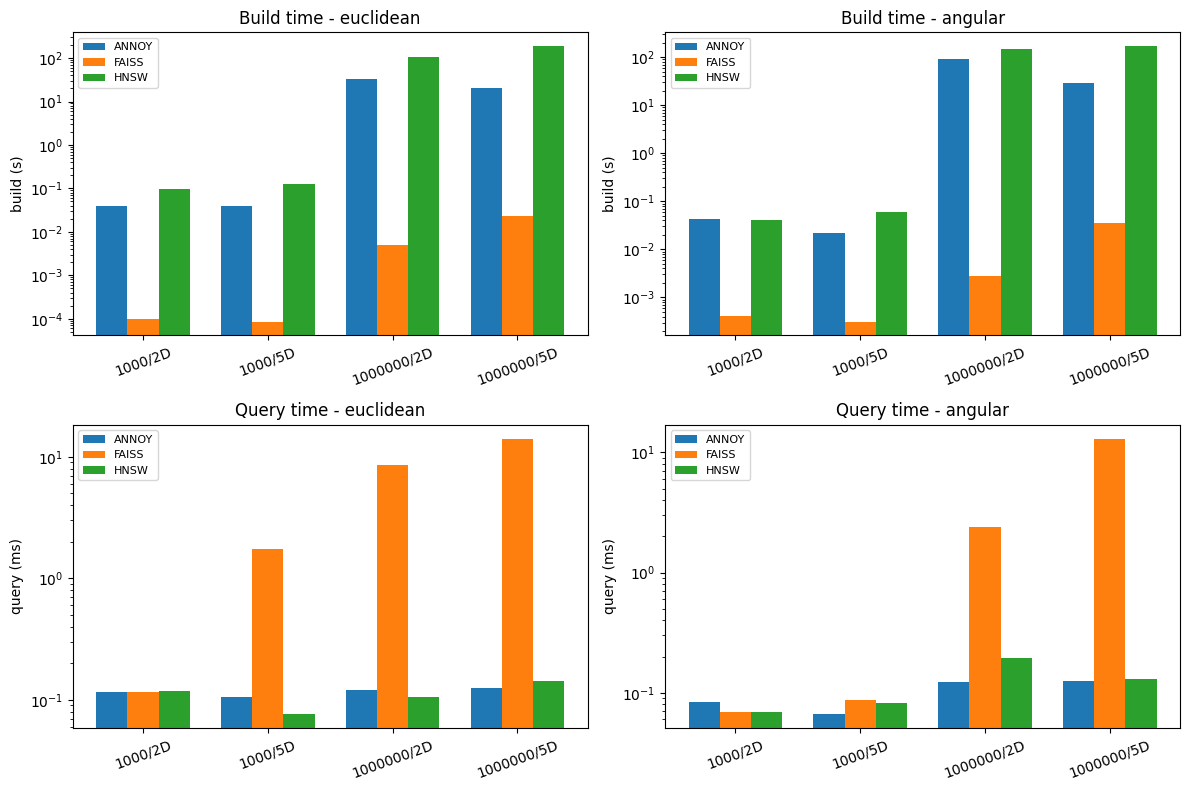

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, metric in zip(axes[0], METRICS):
    sub = df[df["Metric"] == metric]
    x = np.arange(len(sub))
    w = 0.25
    ax.bar(x - w, sub["ANNOY_build_s"], w, label="ANNOY")
    ax.bar(x, sub["FAISS_build_s"], w, label="FAISS")
    ax.bar(x + w, sub["HNSW_build_s"], w, label="HNSW")
    ax.set_xticks(x)
    ax.set_xticklabels(sub["Jumlah Data/Dimensi"], rotation=20)
    ax.set_ylabel("build (s)")
    ax.set_title(f"Build time - {metric}")
    ax.set_yscale("log")
    ax.legend(fontsize=8)

for ax, metric in zip(axes[1], METRICS):
    sub = df[df["Metric"] == metric]
    x = np.arange(len(sub))
    w = 0.25
    ax.bar(x - w, sub["ANNOY_query_ms"], w, label="ANNOY")
    ax.bar(x, sub["FAISS_query_ms"], w, label="FAISS")
    ax.bar(x + w, sub["HNSW_query_ms"], w, label="HNSW")
    ax.set_xticks(x)
    ax.set_xticklabels(sub["Jumlah Data/Dimensi"], rotation=20)
    ax.set_ylabel("query (ms)")
    ax.set_title(f"Query time - {metric}")
    ax.set_yscale("log")
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

## Kesimpulan

In [8]:
# ringkas dari hasil aktual
n1m = df[df["n"] == 1_000_000]
print("Rata2 query di n=1e6 (ms):")
print(n1m[["ANNOY_query_ms", "FAISS_query_ms", "HNSW_query_ms"]].mean().round(3))
print()
print("Rata2 build di n=1e6 (s):")
print(n1m[["ANNOY_build_s", "FAISS_build_s", "HNSW_build_s"]].mean().round(3))
print()

# temuan singkat berdasarkan angka di atas
fastest_q = n1m[["ANNOY_query_ms", "FAISS_query_ms", "HNSW_query_ms"]].mean().idxmin()
slowest_b = n1m[["ANNOY_build_s", "FAISS_build_s", "HNSW_build_s"]].mean().idxmax()
print(f"Query tercepat rata2 di n=1jt: {fastest_q}")
print(f"Build terlama rata2 di n=1jt: {slowest_b}")

Rata2 query di n=1e6 (ms):
ANNOY_query_ms    0.124
FAISS_query_ms    9.539
HNSW_query_ms     0.143
dtype: float64

Rata2 build di n=1e6 (s):
ANNOY_build_s     43.827
FAISS_build_s      0.017
HNSW_build_s     153.444
dtype: float64

Query tercepat rata2 di n=1jt: ANNOY_query_ms
Build terlama rata2 di n=1jt: HNSW_build_s


### Catatan hasil
- Metric yang dicoba: **euclidean (L2)** dan **angular** (Annoy angular / FAISS IP+normalize / HNSW cosine)
- Di data besar (1jt), FAISS Flat build hampir instan tapi query-nya paling lambat (brute force)
- Annoy & HNSW query jauh lebih cepet di n besar; tradeoff-nya build HNSW paling mahal
- Naik dimensi 2D→5D pengaruhnya lebih ke query FAISS Flat; Annoy/HNSW relatif stabil
- Angka di tabel dari run notebook ini (seed=42, k=10, Annoy trees=10, HNSW M=16 ef_c=200 ef=50)